In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

# Load Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

print("Dataset loaded successfully!")


TensorFlow version: 2.21.0
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Dataset loaded successfully!


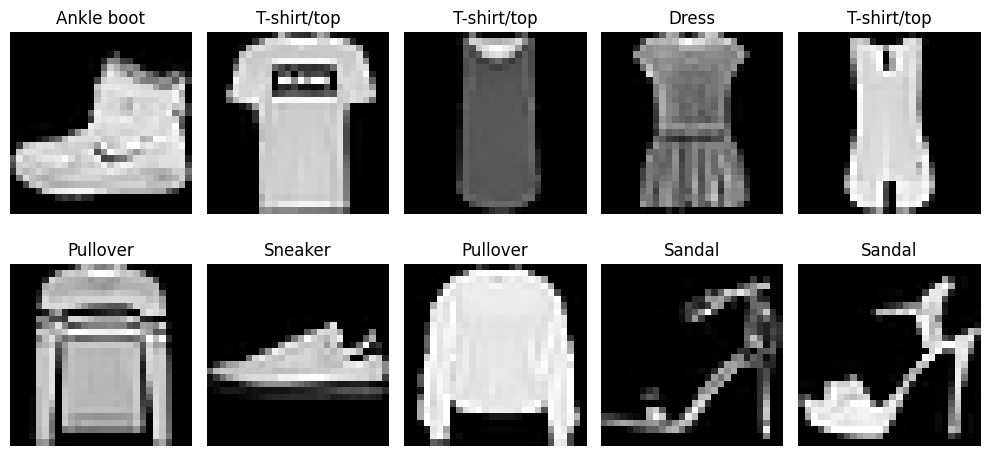

In [2]:

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress',
    'Coat', 'Sandal', 'Shirt', 'Sneaker',
    'Bag', 'Ankle boot'
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()


In [3]:
# Normalize pixel values from 0–255 to 0–1
X_train = X_train / 255.0
X_test = X_test / 255.0

# Add channel dimension for CNN
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Preprocessing completed successfully!")

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)
Preprocessing completed successfully!


In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Create CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(10, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model structure
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 53ms/step - accuracy: 0.7836 - loss: 0.5899 - val_accuracy: 0.8589 - val_loss: 0.3875
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 40s 53ms/step - accuracy: 0.8609 - loss: 0.3863 - val_accuracy: 0.8757 - val_loss: 0.3368
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 40s 53ms/step - accuracy: 0.8782 - loss: 0.3359 - val_accuracy: 0.8853 - val_loss: 0.3081
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 53ms/step - accuracy: 0.8900 - loss: 0.2998 - val_accuracy: 0.8840 - val_loss: 0.3085
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 40s 54ms/step - accuracy: 0.8967 - loss: 0.2760 - val_accuracy: 0.9007 - val_loss: 0.2765
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 40s 52ms/step - accuracy: 0.9039 - loss: 0.2571 - val_accuracy: 0.9072 - val_loss: 0.2630
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step - accuracy: 0.9111 - loss: 0.2385 - val_accuracy: 0.9101 - val_loss: 0.2478
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 53ms/step - accuracy: 0.9170 - loss: 0.2251 - 

In [6]:
 # Evaluate model on test dataset
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9124 - loss: 0.2476
Test Loss: 0.2476060837507248
Test Accuracy: 91.24000072479248 %


In [7]:
import numpy as np

# Predict test images
y_pred = model.predict(X_test)

# Convert probabilities into class labels
y_pred_classes = np.argmax(y_pred, axis=1)

print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred_classes[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Actual labels: [9 2 1 1 6 1 4 6 5 7]
Predicted labels: [9 2 1 1 6 1 4 6 5 7]


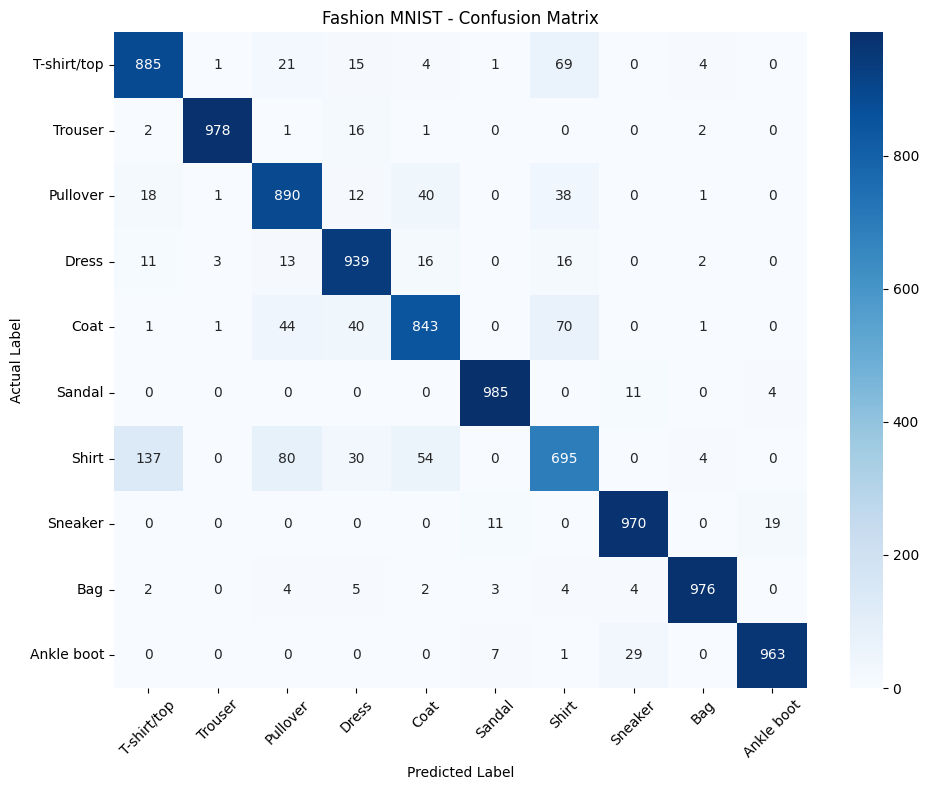

In [8]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Fashion MNIST - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_classes,
    target_names=class_names
))

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.89      0.86      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.85      0.89      0.87      1000
       Dress       0.89      0.94      0.91      1000
        Coat       0.88      0.84      0.86      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.78      0.69      0.73      1000
     Sneaker       0.96      0.97      0.96      1000
         Bag       0.99      0.98      0.98      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



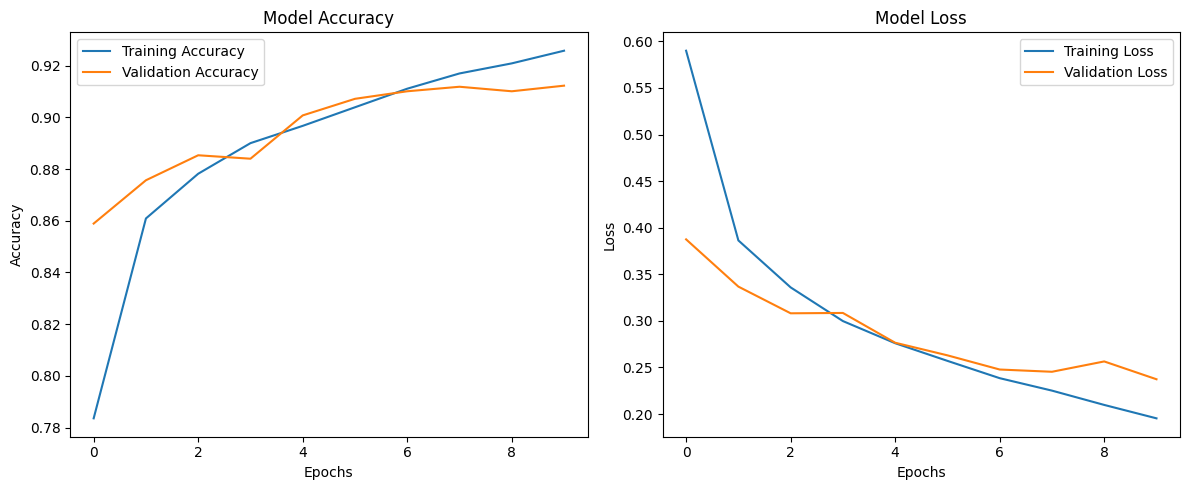

In [10]:
import matplotlib.pyplot as plt

# Create two graphs
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
model.save("fashion_mnist_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [13]:
import os

print(os.path.exists("/content/fashion_mnist_cnn.keras"))

True


In [14]:
from google.colab import files
files.download("/content/fashion_mnist_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
!pip install gradio

In [16]:
import gradio as gr
import numpy as np
from PIL import Image

# Use the CNN model already trained in this notebook

class_names = [
    "T-shirt / Top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle Boot"
]

def predict_fashion(image):
    if image is None:
        return "Please upload an image.", {}

    image = image.convert("L").resize((28, 28))
    image_array = np.array(image).astype("float32") / 255.0
    image_array = image_array.reshape(1, 28, 28, 1)

    predictions = model.predict(image_array, verbose=0)[0]

    predicted_index = int(np.argmax(predictions))
    confidence = float(predictions[predicted_index]) * 100

    result = (
        f"Prediction: {class_names[predicted_index]}\n"
        f"Confidence: {confidence:.2f}%"
    )

    scores = {
        class_names[i]: float(predictions[i])
        for i in range(10)
    }

    return result, scores


with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown("""
    # 👕 Fashion Image Classification
    ### AI-powered clothing recognition

    Upload an image and let the CNN model predict its category.
    """)

    with gr.Row():
        image_input = gr.Image(
            type="pil",
            label="Upload Clothing Image"
        )

        with gr.Column():
            output_text = gr.Textbox(
                label="AI Prediction"
            )

            output_scores = gr.Label(
                label="Prediction Confidence",
                num_top_classes=5
            )

    predict_button = gr.Button(
        "Predict Clothing Category",
        variant="primary"
    )

    predict_button.click(
        predict_fashion,
        inputs=image_input,
        outputs=[output_text, output_scores]
    )

    gr.Markdown(
        "Developed using TensorFlow, CNN and Fashion-MNIST."
    )

demo.launch(share=True)

/tmp/ipykernel_3708/1723005655.py:46: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9c520661b177ca1ab3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
